# Entrega 02: Análise de Regressão dos Dados

Na entrega anterior olhamos para a distribuição de cada indicador financeiro separadamente: média, mediana, dispersão, outliers. Agora o objetivo é entender como os indicadores se relacionam entre si. Para isso vamos ajustar um modelo de regressão linear, interpretar o que os coeficientes dizem, verificar se o ajuste é bom e registrar as limitações que encontramos pelo caminho.

A base usada é a mesma da entrega anterior, já tratada e normalizada: `Demonstrativo_Normalizado.csv`, com 14.400 linhas (1.200 cenários simulados por Monte Carlo, ao longo de 12 anos de concessão) e os indicadores financeiros organizados em colunas.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

pd.set_option('display.width', 150)
pd.set_option('display.max_columns', 20)

In [ ]:
df = pd.read_csv('Demonstrativo_Normalizado.csv', sep=';', decimal=',', encoding='utf-8-sig')
df['Ano'] = df['Ano'].astype(int)
df['Cenario'] = df['Cenario'].astype(int)

print('Linhas e colunas:', df.shape)
df[['Ano', 'Cenario', 'DRE - Receita', 'DRE - EBITDA', 'DRE - Resultado Líquido',
    'FLU - Geração de Caixa', 'FLU - Saldo Final', 'BAL - Total do Ativo']].head()

Linhas e colunas: (14400, 71)


,Ano,Cenario,DRE - Receita,DRE - EBITDA,DRE - Resultado Líquido,FLU - Geração de Caixa,FLU - Saldo Final,BAL - Total do Ativo
0,1,1,6.722729e+09,5.188381e+09,2.443243e+09,4.306498e+08,1.205265e+09,1.063113e+10
1,1,2,6.703608e+09,5.172388e+09,2.436562e+09,4.243157e+08,1.198931e+09,1.062391e+10
2,1,3,6.676361e+09,5.149189e+09,2.434790e+09,4.211763e+08,1.195792e+09,1.062317e+10
3,1,4,6.672623e+09,5.146146e+09,2.435385e+09,4.216127e+08,1.196228e+09,1.062329e+10
4,1,5,6.660653e+09,5.136879e+09,2.416009e+09,4.052842e+08,1.179899e+09,1.060179e+10


## 1. Escolhendo as variáveis do modelo



In [ ]:
indicadores = ['Ano', 'Cenario', 'DRE - Receita', 'DRE - EBITDA', 'DRE - Resultado Líquido',
               'FLU - Geração de Caixa', 'FLU - Saldo Final', 'BAL - Total do Ativo']

corr = df[indicadores].corr(numeric_only=True).round(3)
corr

,Ano,Cenario,DRE - Receita,DRE - EBITDA,DRE - Resultado Líquido,FLU - Geração de Caixa,FLU - Saldo Final,BAL - Total do Ativo
Ano,1.000,0.000,0.913,0.874,0.878,-0.172,0.276,-0.852
Cenario,0.000,1.000,-0.008,-0.005,-0.027,0.019,-0.163,-0.027
DRE - Receita,0.913,-0.008,1.000,0.990,0.992,-0.373,0.225,-0.922
DRE - EBITDA,0.874,-0.005,0.990,1.000,0.997,-0.471,0.129,-0.951
DRE - Resultado Líquido,0.878,-0.027,0.992,0.997,1.000,-0.460,0.151,-0.946
FLU - Geração de Caixa,-0.172,0.019,-0.373,-0.471,-0.460,1.000,0.564,0.578
FLU - Saldo Final,0.276,-0.163,0.225,0.129,0.151,0.564,1.000,0.131
BAL - Total do Ativo,-0.852,-0.027,-0.922,-0.951,-0.946,0.578,0.131,1.000


Dá para ver um problema logo de cara: Receita, EBITDA e Resultado Líquido se correlacionam entre si acima de 0,99. Isso faz sentido pela própria estrutura da demonstração de resultado, o EBITDA parte da Receita, e o Resultado Líquido parte do EBITDA, então os três crescem praticamente juntos ao longo dos anos da concessão. Se a gente usasse, por exemplo, EBITDA para prever Resultado Líquido, o modelo teria um R² artificialmente perto de 1, mas isso não estaria revelando relação nenhuma, só estaria reconstruindo uma identidade contábil.

Cenário, por outro lado, não se correlaciona com quase nada (todos os valores ficam perto de zero). Isso também faz sentido: o número do cenário é só um identificador da simulação, não carrega informação financeira.

A variável que mais chama atenção é a Geração de Caixa. Ela tem uma correlação moderada e negativa com Resultado Líquido (-0,46) e fraca com Ano (-0,17), bem diferente do padrão quase determinístico das outras três. Isso indica que a Geração de Caixa segue uma lógica própria, provavelmente ligada a itens que não passam diretamente pelo resultado contábil, como capital de giro e o momento dos desembolsos de caixa. É uma relação real para investigar, não uma redundância.

Por isso, o modelo escolhido para esta entrega é:

**Geração de Caixa = β₀ + β₁ × Resultado Líquido + β₂ × Ano + erro**

A ideia é entender o quanto da variação na geração de caixa está associada ao resultado contábil do período e ao avanço no tempo da concessão, mantendo a outra variável fixa.

Antes de ajustar o modelo, vale olhar a relação entre as variáveis em um gráfico de dispersão.

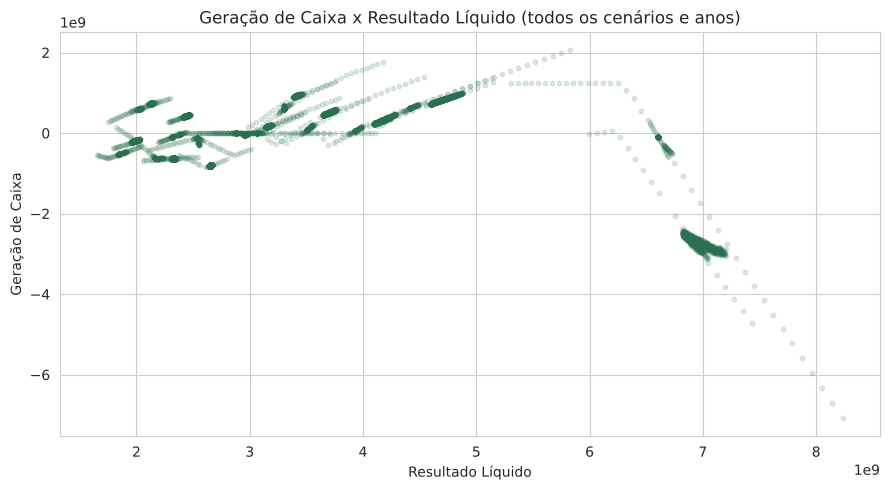

In [ ]:
plt.figure()
plt.scatter(df['DRE - Resultado Líquido'], df['FLU - Geração de Caixa'], alpha=0.15, s=10, color='#2a6f4f')
plt.xlabel('Resultado Líquido')
plt.ylabel('Geração de Caixa')
plt.title('Geração de Caixa x Resultado Líquido (todos os cenários e anos)')
plt.ticklabel_format(style='scientific', axis='both', scilimits=(0,0))
plt.tight_layout()
plt.show()

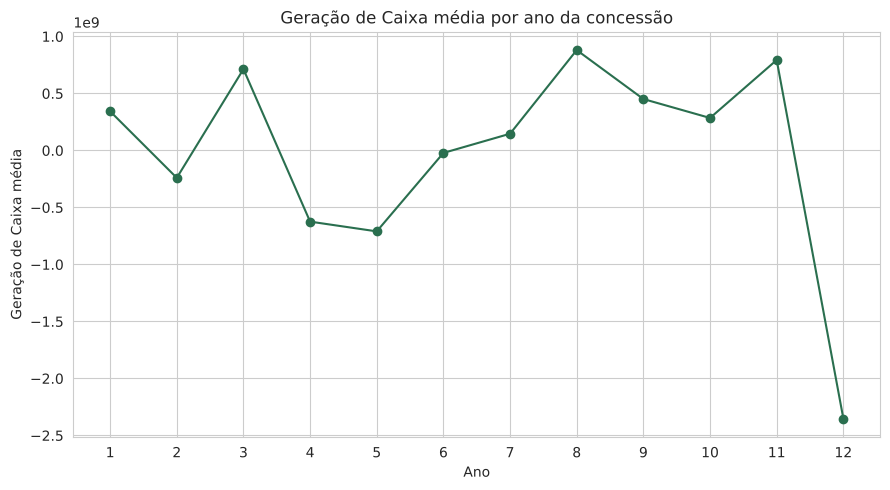

In [ ]:
plt.figure()
medias_por_ano = df.groupby('Ano')['FLU - Geração de Caixa'].mean()
plt.plot(medias_por_ano.index, medias_por_ano.values, marker='o', color='#2a6f4f')
plt.xlabel('Ano')
plt.ylabel('Geração de Caixa média')
plt.title('Geração de Caixa média por ano da concessão')
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

O gráfico de dispersão mostra uma nuvem de pontos com inclinação negativa, mas bem mais espalhada do que seria o caso de Receita, EBITDA e Resultado Líquido entre si. Já o gráfico por ano mostra que a geração de caixa média cresce ao longo da concessão, com uma queda nos últimos anos, quando o contrato está se encerrando. Isso sugere que o ano sozinho já carrega parte da explicação, e é por isso que ele entra no modelo junto com o Resultado Líquido.

## 2. Ajustando o modelo de regressão

Com as variáveis definidas, ajustamos a regressão linear múltipla usando mínimos quadrados ordinários (OLS).

In [ ]:
y = df['FLU - Geração de Caixa']
X = df[['DRE - Resultado Líquido', 'Ano']]
X = sm.add_constant(X)

modelo = sm.OLS(y, X).fit()
print(modelo.summary())

                              OLS Regression Results                              
Dep. Variable:     FLU - Geração de Caixa   R-squared:                       0.447
Model:                                OLS   Adj. R-squared:                  0.447
Method:                     Least Squares   F-statistic:                     5814.
Date:                    Sun, 25 Oct 2026   Prob (F-statistic):               0.00
Time:                            12:00:26   Log-Likelihood:            -3.1332e+05
No. Observations:                   14400   AIC:                         6.266e+05
Df Residuals:                       14397   BIC:                         6.267e+05
Df Model:                               2                                         
Covariance Type:                nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------

## 3. Interpretando os coeficientes

| Coeficiente | Valor | Leitura |
|---|---|---|
| Intercepto (β₀) | ≈ 1,34 bilhão | geração de caixa esperada quando Resultado Líquido e Ano são zero (não tem leitura prática isolada, serve só para ancorar a reta) |
| Resultado Líquido (β₁) | ≈ -0,93 | mantendo o ano fixo, cada R$ 1 a mais de resultado líquido está associado, em média, a uma queda de R$ 0,93 na geração de caixa |
| Ano (β₂) | ≈ 269 milhões | mantendo o resultado líquido fixo, cada ano adicional de concessão está associado a um aumento médio de R$ 269 milhões na geração de caixa |

O sinal negativo do Resultado Líquido chama atenção, porque a princípio seria de esperar que mais lucro significasse mais caixa gerado. Mas isso é o mesmo tipo de armadilha que a gente já tinha visto na entrega anterior com a dispersão pooled: quando o modelo usa todos os anos e cenários juntos, parte do que parece ser o efeito do Resultado Líquido na verdade é o efeito do tempo passando. Receita, EBITDA e Resultado Líquido crescem de forma quase determinística ano a ano, enquanto a Geração de Caixa tem uma dinâmica diferente (picos em certos anos, queda no fim da concessão). O modelo, ao tentar separar o que é efeito do Ano do que é efeito do Resultado Líquido, acaba atribuindo um coeficiente negativo ao Resultado Líquido para compensar o forte efeito positivo do Ano. Isso é discutido com mais detalhe na seção de limitações.

De qualquer forma, os dois coeficientes são estatisticamente significativos (p-valor praticamente zero para ambos), então a relação não é fruto do acaso dentro da amostra, mesmo que a leitura causal precise ser feita com cautela.

## 4. Qualidade do ajuste

In [ ]:
print(f"R-quadrado:            {modelo.rsquared:.3f}")
print(f"R-quadrado ajustado:   {modelo.rsquared_adj:.3f}")
print(f"Estatistica F:         {modelo.fvalue:.1f}")
print(f"P-valor do teste F:    {modelo.f_pvalue:.2e}")
print(f"Numero de observacoes: {int(modelo.nobs)}")

R-quadrado:            0.447
R-quadrado ajustado:   0.447
Estatistica F:         5814.2
P-valor do teste F:    0.00e+00
Numero de observacoes: 14400


O modelo explica cerca de 45% da variação da Geração de Caixa (R² = 0,447). É um ajuste moderado: nem perto de 1 (o que seria sinal de uma identidade contábil disfarçada, como aconteceria se usássemos EBITDA no lugar de Resultado Líquido) nem perto de zero (o que indicaria que as variáveis escolhidas não têm relação nenhuma com o que queremos prever). O teste F confirma que o modelo como um todo é estatisticamente significativo.

Isso quer dizer que pouco mais da metade da variação na Geração de Caixa fica fora do que o Resultado Líquido e o Ano conseguem explicar. Faz sentido: geração de caixa depende de outros fatores que não estão no modelo, como variação de capital de giro, pagamentos e recebimentos que não coincidem no tempo com o resultado contábil, e outras decisões financeiras específicas de cada cenário simulado.

### 4.1 Testes de hipótese sobre o modelo

Dá para olhar a regressão também como um conjunto de testes de hipótese, o mesmo raciocínio das aulas de inferência.

Para cada coeficiente, o teste t compara duas hipóteses:

- H0: o coeficiente é zero (a variável não ajuda a explicar a Geração de Caixa, com a outra variável fixa)
- H1: o coeficiente é diferente de zero

A estatística t é o coeficiente dividido pelo seu erro-padrão. Se o valor-p for menor que 0,05, rejeitamos H0.

Para o modelo como um todo, o teste F usa H0: todos os coeficientes (menos o intercepto) são zero, ou seja, o modelo não explica nada além da média.

In [ ]:
alfa = 0.05
tabela_testes = pd.DataFrame({
    'Coeficiente': modelo.params,
    'Erro-padrão': modelo.bse,
    'Estatística t': modelo.tvalues,
    'Valor-p': modelo.pvalues,
    'IC 95% inferior': modelo.conf_int()[0],
    'IC 95% superior': modelo.conf_int()[1],
})
tabela_testes['Decisão (alfa = 0,05)'] = np.where(tabela_testes['Valor-p'] < alfa, 'rejeita H0', 'não rejeita H0')
pd.options.display.float_format = '{:,.4f}'.format
print(tabela_testes.to_string())
pd.reset_option('display.float_format')

print()
print(f"Teste F: estatística = {modelo.fvalue:.1f}, valor-p = {modelo.f_pvalue:.2e}")
print('Decisão:', 'rejeita H0' if modelo.f_pvalue < alfa else 'não rejeita H0')

                               Coeficiente     Erro-padrão  Estatística t  Valor-p    IC 95% inferior    IC 95% superior Decisão (alfa = 0,05)
const                   1,338,013,850.6930 15,871,393.4400        84.3035   0.0000 1,306,903,875.7350 1,369,123,825.6511            rejeita H0
DRE - Resultado Líquido            -0.9278          0.0089      -104.2207   0.0000            -0.9452            -0.9103            rejeita H0
Ano                       268,959,490.4411  3,436,561.2220        78.2641   0.0000   262,223,387.9079   275,695,592.9744            rejeita H0

Teste F: estatística = 5814.2, valor-p = 0.00e+00
Decisão: rejeita H0


Nos dois testes t o valor-p fica praticamente em zero, então rejeitamos H0 para o Resultado Líquido e para o Ano. Os intervalos de confiança de 95% não incluem o zero, o que diz a mesma coisa de outro jeito. O teste F também rejeita H0, então o modelo explica mais do que apenas a média da Geração de Caixa.

Um cuidado: com 14.400 observações, até efeitos pequenos dão valor-p minúsculo. Por isso o valor-p sozinho não basta, e é bom olhar junto o tamanho do efeito e o R². Além disso, os diagnósticos da próxima seção mostram que as premissas do OLS não valem por inteiro, então esses valores-p devem ser lidos como aproximados.

## 5. Diagnósticos do modelo

Além de olhar para o R² e para os coeficientes, é importante verificar se as premissas da regressão linear estão sendo respeitadas. Vamos checar resíduos, normalidade, variância constante e multicolinearidade, um diagnóstico de cada vez.

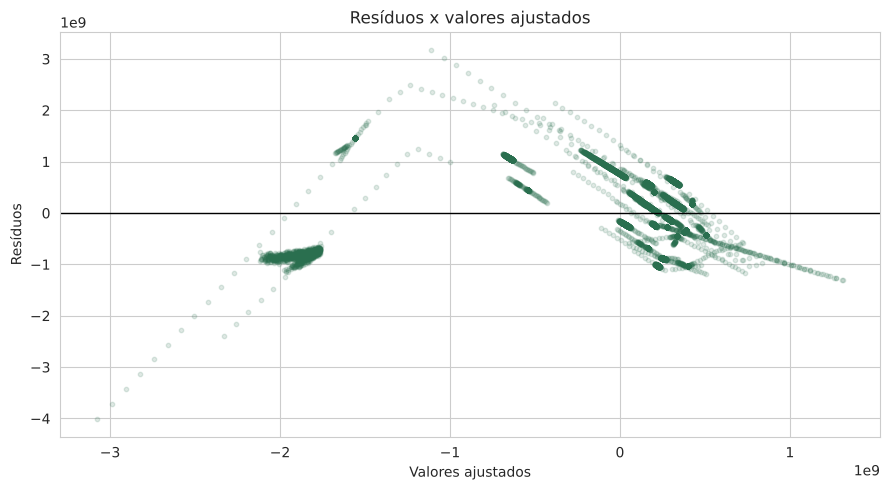

In [ ]:
residuos = modelo.resid
ajustados = modelo.fittedvalues

plt.figure()
plt.scatter(ajustados, residuos, alpha=0.15, s=10, color='#2a6f4f')
plt.axhline(0, color='black', linewidth=1)
plt.xlabel('Valores ajustados')
plt.ylabel('Resíduos')
plt.title('Resíduos x valores ajustados')
plt.tight_layout()
plt.show()

Se as premissas da regressão estivessem bem respeitadas, essa nuvem de pontos deveria estar espalhada de forma mais ou menos uniforme ao redor da linha zero, sem nenhum padrão visível. Aqui dá para notar uma leve curvatura e um espalhamento que muda conforme o valor ajustado, o que já é um indício de que a relação entre as variáveis não é perfeitamente linear e de que a variância dos resíduos não é constante.

<Figure size 900x500 with 0 Axes>

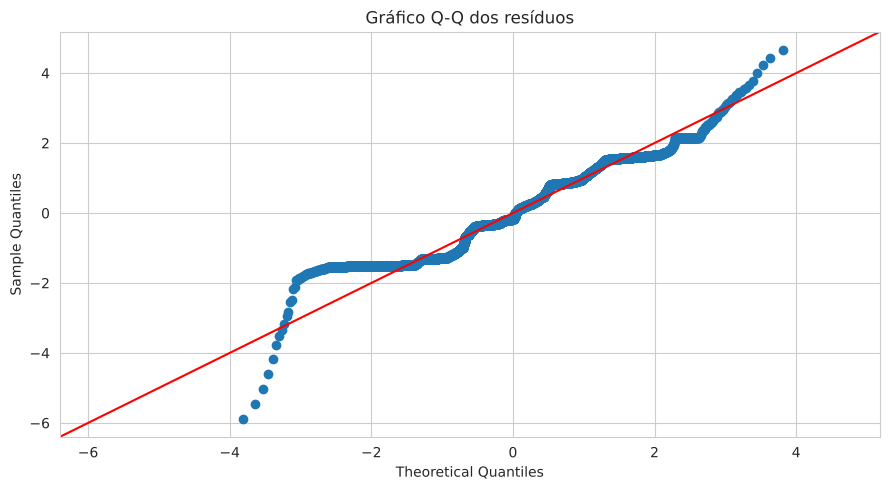

In [ ]:
plt.figure()
sm.qqplot(residuos, line='45', fit=True)
plt.title('Gráfico Q-Q dos resíduos')
plt.tight_layout()
plt.show()

No gráfico Q-Q, se os resíduos fossem normalmente distribuídos, os pontos ficariam em cima da linha diagonal. Aqui eles se afastam da linha principalmente nas pontas (caudas), o que indica que a distribuição dos resíduos tem caudas mais pesadas do que uma normal, ou seja, valores bem distantes da média aparecem com mais frequência do que o esperado.

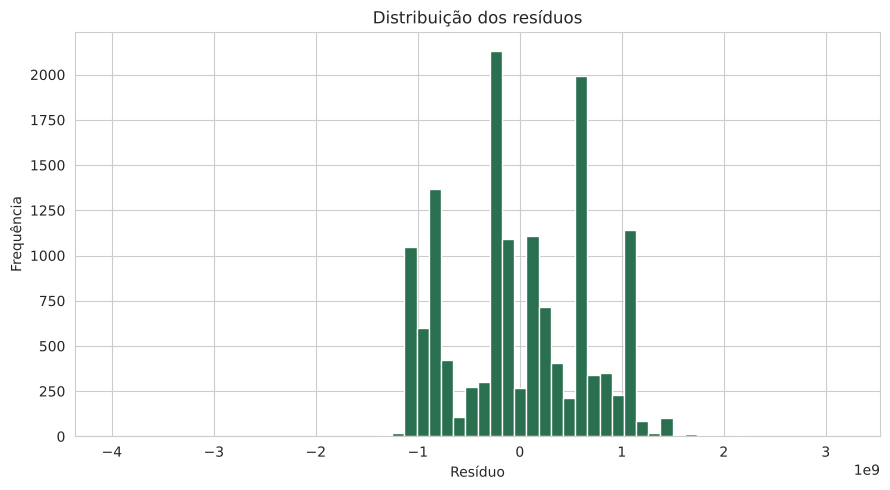

In [ ]:
plt.figure()
plt.hist(residuos, bins=60, color='#2a6f4f', edgecolor='white')
plt.xlabel('Resíduo')
plt.ylabel('Frequência')
plt.title('Distribuição dos resíduos')
plt.tight_layout()
plt.show()

In [ ]:
bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(residuos, X)
shapiro_stat, shapiro_p = stats.shapiro(residuos.sample(5000, random_state=42))

print(f"Teste de Breusch-Pagan (heterocedasticidade): estatistica = {bp_lm:.1f}, p-valor = {bp_p:.2e}")
print(f"Teste de Shapiro-Wilk (normalidade, amostra de 5000): estatistica = {shapiro_stat:.3f}, p-valor = {shapiro_p:.2e}")
print(f"Durbin-Watson (autocorrelacao): {sm.stats.stattools.durbin_watson(residuos):.3f}")

Teste de Breusch-Pagan (heterocedasticidade): estatistica = 2620.0, p-valor = 0.00e+00
Teste de Shapiro-Wilk (normalidade, amostra de 5000): estatistica = 0.961, p-valor = 8.12e-35
Durbin-Watson (autocorrelacao): 0.032


Os três testes formais confirmam o que os gráficos já sugeriam:

- O teste de Breusch-Pagan rejeita a hipótese de variância constante (p-valor praticamente zero), confirmando heterocedasticidade.
- O teste de Shapiro-Wilk rejeita a hipótese de normalidade dos resíduos, confirmando o que o gráfico Q-Q mostrou nas caudas.
- O valor de Durbin-Watson próximo de zero indica autocorrelação positiva forte nos resíduos, o que é esperado aqui: a base está organizada por ano e depois por cenário, então observações vizinhas tendem a se parecer mais entre si do que observações distantes.

Nenhum desses resultados invalida o modelo, mas eles mostram que os erros-padrão e os p-valores reportados pelo OLS devem ser interpretados com cautela, porque o teste F e os testes t assumem resíduos independentes e com variância constante. Isso está detalhado na seção de limitações.

In [ ]:
vif = pd.DataFrame({
    'Variável': X.columns,
    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
vif

,Variável,VIF
0,const,1.000000
1,DRE - Resultado Líquido,4.366696
2,Ano,4.366696


O VIF do Resultado Líquido e do Ano fica em torno de 4,4. Como regra prática, valores de VIF acima de 10 costumam ser considerados preocupantes, e valores acima de 5 já merecem atenção. Aqui o valor está abaixo desse limite mais rígido, mas ainda assim indica alguma colinearidade entre as duas variáveis explicativas (afinal, o Resultado Líquido também cresce com o Ano), o que é mais um motivo para interpretar o coeficiente do Resultado Líquido com cuidado.

## 6. Limitações da análise

- **Pooling de anos e cenários**: o modelo foi ajustado usando os 14.400 registros juntos (12 anos x 1.200 cenários), sem considerar que cada ano tem sua própria dinâmica. Isso é o mesmo tipo de cuidado que já tínhamos identificado na análise descritiva: misturar períodos diferentes pode distorcer a leitura de uma relação. O sinal negativo do coeficiente do Resultado Líquido é provavelmente um reflexo disso, e não uma relação de causa e efeito direta.
- **Heterocedasticidade e não normalidade dos resíduos**: confirmadas pelos testes de Breusch-Pagan e Shapiro-Wilk. Isso significa que os p-valores e intervalos de confiança do modelo são aproximados, não exatos.
- **Autocorrelação dos resíduos**: o Durbin-Watson próximo de zero mostra que os resíduos não são independentes entre si, o que também compromete a validade formal dos testes de significância, mesmo que as estimativas dos coeficientes continuem sendo válidas.
- **Variáveis fora do modelo**: só duas variáveis foram usadas (Resultado Líquido e Ano). Pouco mais da metade da variação da Geração de Caixa não é explicada por elas, o que indica que outros fatores (capital de giro, timing de pagamentos e recebimentos, decisões específicas de cada cenário) também têm papel relevante.
- **Relação linear assumida**: o modelo assume que a relação entre as variáveis é linear. O leve padrão de curvatura visto no gráfico de resíduos sugere que uma relação não linear poderia descrever melhor os dados, algo que poderia ser explorado em uma análise futura.
- **Multicolinearidade moderada**: o VIF em torno de 4,4 mostra que Resultado Líquido e Ano compartilham parte da sua variação, o que dificulta isolar o efeito individual de cada um com total precisão.

## 7. Síntese

O modelo de regressão ajustado explica cerca de 45% da variação da Geração de Caixa a partir do Resultado Líquido e do Ano da concessão, um ajuste moderado e estatisticamente significativo, mas longe de perfeito. O coeficiente do Ano confirma que a geração de caixa tende a crescer ao longo da concessão, enquanto o coeficiente negativo do Resultado Líquido chama atenção para o fato de que lucro contábil e caixa gerado não andam necessariamente juntos dentro de um mesmo ano, até porque a correlação simples entre as duas variáveis já é negativa.

Os diagnósticos mostraram que o modelo não respeita totalmente as premissas clássicas da regressão linear (variância constante, normalidade e independência dos resíduos), o que é esperado em dados de simulação organizados por ano e cenário sem uma estrutura de painel propriamente dita. Ainda assim, o exercício cumpriu o papel desta entrega: explorar uma relação real entre variáveis financeiras, evitando o erro de montar um modelo tautológico a partir de variáveis quase idênticas entre si (como seria o caso de usar Receita ou EBITDA para prever Resultado Líquido), e deixando registradas as limitações que qualquer leitura dos coeficientes precisa levar em conta.